# 01 · Caso de negocio — AccessGuard AI (gobernanza de accesos IAM)

**Hito H1 · Clase 2 (30 de octubre).** Dataset: *Amazon Employee Access Challenge* (`Data/train.csv`, `Data/test.csv`).

Este notebook convierte la ficha del caso en números: la pregunta de negocio, la variable respuesta, el costo de
equivocarse en cada sentido (matriz costo/beneficio), las líneas base sin modelo y la métrica de éxito.

> **Honestidad sobre los datos.** El dataset trae solicitudes y su resultado (`ACTION`), pero **no trae costos**.
> Los valores en dólares de este notebook son **supuestos de trabajo** (viven en `config/settings.py`) que el área de
> Seguridad/Riesgos debe validar. Por eso hay un análisis de sensibilidad: la conclusión debe resistir si los costos cambian.

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path[:0] = [str(ROOT), str(ROOT / "src")]   # permite importar config/ y src/accessguard

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import settings as S

pd.set_option("display.max_columns", 30, "display.width", 140)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold", "axes.titlesize": 11,
})
BLUE, ORANGE, GRAY = "#2A6FBB", "#D9622B", "#8A8F98"   # aprobado / denegado / neutro

## 1. El problema de negocio

**Contexto.** Cada vez que un empleado necesita acceder a un recurso corporativo (una aplicación, un repositorio, un
sistema), alguien de TI/Seguridad revisa la solicitud y la aprueba o la deniega. A escala corporativa, esa revisión
manual es lenta y cara, y las decisiones son inconsistentes entre revisores.

**Pregunta de negocio (una frase).** *¿Podemos decidir automáticamente, con el perfil del rol del empleado y el recurso
pedido, qué solicitudes de acceso se aprueban y cuáles se deniegan, sin conceder accesos indebidos y sin bloquear a quien sí debe trabajar?*

| | |
|---|---|
| **Quién usa el resultado** | Equipo de Gobierno de Accesos (IAM) y Seguridad de la información |
| **Qué decisión toma** | Aprobar automáticamente, denegar automáticamente o (en una fase posterior) escalar a revisión humana |
| **Qué cambia respecto de hoy** | Se revisa a mano solo la zona gris; el resto se resuelve en segundos y con un criterio uniforme |

In [2]:
train = pd.read_csv(S.TRAIN_PATH)
test = pd.read_csv(S.TEST_PATH)
print(f"train: {train.shape[0]:,} solicitudes x {train.shape[1]} columnas (con etiqueta)")
print(f"test : {test.shape[0]:,} solicitudes x {test.shape[1]} columnas (SIN etiqueta: no sirve para medir)")
train.head()

train: 32,769 solicitudes x 10 columnas (con etiqueta)
test : 58,921 solicitudes x 10 columnas (SIN etiqueta: no sirve para medir)


,ACTION,RESOURCE,MGR_ID,ROLE_ROLLUP_1,ROLE_ROLLUP_2,ROLE_DEPTNAME,ROLE_TITLE,ROLE_FAMILY_DESC,ROLE_FAMILY,ROLE_CODE
0,1,39353,85475,117961,118300,123472,117905,117906,290919,117908
1,1,17183,1540,117961,118343,123125,118536,118536,308574,118539
2,1,36724,14457,118219,118220,117884,117879,267952,19721,117880
3,1,36135,5396,117961,118343,119993,118321,240983,290919,118322
4,1,42680,5905,117929,117930,119569,119323,123932,19793,119325


## 2. Unidad de análisis y variable respuesta

- **Una fila es una solicitud de acceso**: un empleado, identificado por su rol (`ROLE_*`) y su gerente (`MGR_ID`), pide
  acceso a un recurso (`RESOURCE`). El dataset es anónimo: **no hay nombres ni documentos**, solo códigos numéricos.
- **Variable respuesta: `ACTION`** → `1` = acceso **aprobado**, `0` = acceso **denegado**.
  Convención de este proyecto: la **clase positiva es `1` (aprobar)**. Un modelo que dice "1" está *concediendo* el acceso.
- **Tipo de problema:** clasificación binaria, muy desbalanceada.
- **Entidad que se repite:** `MGR_ID` y `RESOURCE` aparecen en muchas filas. Eso condiciona cómo se parte el dato (ver `03_preprocesamiento`).

Aprobadas (1): 30,872 (94.21%)   Denegadas (0): 1,897 (5.79%)


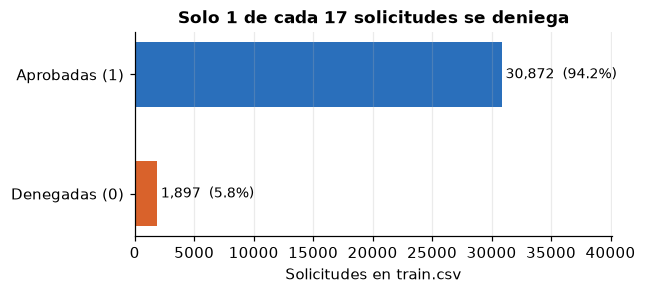

In [3]:
vc = train[S.TARGET].value_counts().sort_index()
rate_deny = vc[0] / len(train)
print(f"Aprobadas (1): {vc[1]:,} ({1-rate_deny:.2%})   Denegadas (0): {vc[0]:,} ({rate_deny:.2%})")

fig, ax = plt.subplots(figsize=(5.6, 2.4))
ax.barh(["Denegadas (0)", "Aprobadas (1)"], [vc[0], vc[1]], color=[ORANGE, BLUE], height=0.55)
for y, v in enumerate([vc[0], vc[1]]):
    ax.text(v + 300, y, f"{v:,}  ({v/len(train):.1%})", va="center", fontsize=9)
ax.set_xlim(0, vc.max() * 1.3); ax.set_xlabel("Solicitudes en train.csv"); ax.grid(axis="y", visible=False)
ax.set_title("Solo 1 de cada 17 solicitudes se deniega")
plt.show()

**Lectura.** Si el modelo aprobara *todo*, acertaría ~94 % de las veces y aun así sería inútil: **la exactitud (accuracy) no sirve
como métrica** aquí. Lo que importa es *qué errores* comete y *cuánto cuestan*.

## 3. Los dos errores y su costo (matriz costo/beneficio)

Con la clase positiva = "aprobar":

| | **Realidad: debía aprobarse (1)** | **Realidad: debía denegarse (0)** |
|---|---|---|
| **Modelo aprueba (1)** | ✅ Verdadero Positivo — acceso concedido a quien lo necesita. Costo ≈ 0 | ❌ **Falso Positivo (FP) = concesión indebida.** Un acceso que no debía darse queda abierto: riesgo de fuga de datos, fraude, incumplimiento (SOX/ISO 27001) |
| **Modelo deniega (0)** | ❌ **Falso Negativo (FN) = bloqueo a usuario legítimo.** Alguien que debía trabajar queda parado: ticket, escalamiento, horas perdidas | ✅ Verdadero Negativo — acceso indebido evitado. Costo ≈ 0 |

**¿Cuál error es peor?** El FP. Un bloqueo legítimo se corrige en horas (un ticket); un acceso indebido puede pasar
inadvertido meses y su costo potencial es de otro orden de magnitud. Los valores siguientes son **hipótesis a validar**:

In [4]:
C_FN, C_FP, C_REV = S.COST_FN, S.COST_FP, S.COST_REVIEW

cost_matrix = pd.DataFrame(
    [[0.0, C_FP], [C_FN, 0.0]],
    index=["Modelo aprueba (1)", "Modelo deniega (0)"],
    columns=["Realidad: aprobar (1)", "Realidad: denegar (0)"],
)
print("Costo por decisión (USD) — SUPUESTOS a validar con Seguridad/Riesgos")
display(cost_matrix.style.format("${:,.0f}"))
print(f"\nRevisión manual de una solicitud (analista, ~15 min): ${C_REV:,.0f}")
print(f"Razón C_FP / C_FN = {C_FP / C_FN:.0f}  → una concesión indebida cuesta {C_FP / C_FN:.0f} bloqueos legítimos")

Costo por decisión (USD) — SUPUESTOS a validar con Seguridad/Riesgos


,Realidad: aprobar (1),Realidad: denegar (0)
Modelo aprueba (1),$0,"$2,000"
Modelo deniega (0),$40,$0



Revisión manual de una solicitud (analista, ~15 min): $6
Razón C_FP / C_FN = 50  → una concesión indebida cuesta 50 bloqueos legítimos


**Qué implica la razón de costos: el umbral de decisión.** Si el modelo estima `p = P(aprobar)`, conviene aprobar
solo si el costo esperado de aprobar, `(1 − p)·C_FP`, es menor que el de denegar, `p·C_FN`. Despejando:

$$\text{aprobar si } p \;\ge\; t^* = \frac{C_{FP}}{C_{FP} + C_{FN}}$$

Con costos simétricos el umbral sería 0,5. Con la asimetría de este caso, **el modelo debe estar muy seguro (p muy alta) para aprobar**.

In [5]:
t_star = C_FP / (C_FP + C_FN)
print(f"Umbral óptimo teórico t* = {t_star:.4f}  (aprobar solo si la probabilidad de 'aprobar' ≥ {t_star:.2%})")

ratios = [1, 5, 10, 25, 50, 100, 250]
sens = pd.DataFrame({
    "Razón C_FP/C_FN": ratios,
    "Umbral t*": [r / (r + 1) for r in ratios],
    "Costo por solicitud si se aprueba todo": [rate_deny * C_FN * r for r in ratios],
})
sens["¿Revisar a mano sale más barato que aprobar todo?"] = np.where(sens.iloc[:, 2] > C_REV, "sí", "no")
display(sens.style.format({"Umbral t*": "{:.3f}", "Costo por solicitud si se aprueba todo": "${:,.2f}"}).hide(axis="index"))
print(sens.round(3).to_string(index=False))

Umbral óptimo teórico t* = 0.9804  (aprobar solo si la probabilidad de 'aprobar' ≥ 98.04%)


Razón C_FP/C_FN,Umbral t*,Costo por solicitud si se aprueba todo,¿Revisar a mano sale más barato que aprobar todo?
1,0.500,$2.32,no
5,0.833,$11.58,sí
10,0.909,$23.16,sí
25,0.962,$57.89,sí
50,0.980,$115.78,sí
100,0.990,$231.56,sí
250,0.996,$578.90,sí


 Razón C_FP/C_FN  Umbral t*  Costo por solicitud si se aprueba todo ¿Revisar a mano sale más barato que aprobar todo?
               1      0.500                                   2.316                                                no
               5      0.833                                  11.578                                                sí
              10      0.909                                  23.156                                                sí
              25      0.962                                  57.890                                                sí
              50      0.980                                 115.780                                                sí
             100      0.990                                 231.560                                                sí
             250      0.996                                 578.901                                                sí


**Lectura.** Cuanto más grave es el FP respecto del FN, más alto el umbral y más caro es "aprobar todo". Con razón ≥ 5
la política de aprobar todo ya cuesta más que revisar cada solicitud a mano: **esa es la razón de ser del proyecto**.

## 4. Impacto en el negocio: ¿cuánto cuesta el proceso actual?

In [6]:
n_ref = len(test)   # volumen de REFERENCIA: usamos el tamaño de test.csv como "un periodo" de solicitudes
manual_cost = n_ref * C_REV
approve_all_cost = n_ref * rate_deny * C_FP
print(f"Volumen de referencia: {n_ref:,} solicitudes (tamaño de test.csv; no es un dato de facturación real)")
print(f"Revisión manual del 100 %           : ${manual_cost:>12,.0f}   (supone un revisor sin errores — cota optimista)")
print(f"Aprobar todo (sin controles)        : ${approve_all_cost:>12,.0f}   ({rate_deny:.2%} de concesiones indebidas esperadas)")
print(f"Horas-analista de la revisión manual: {n_ref * 15 / 60:,.0f} h  (a 15 min por solicitud)")

Volumen de referencia: 58,921 solicitudes (tamaño de test.csv; no es un dato de facturación real)
Revisión manual del 100 %           : $     353,526   (supone un revisor sin errores — cota optimista)
Aprobar todo (sin controles)        : $   6,821,883   (5.79% de concesiones indebidas esperadas)
Horas-analista de la revisión manual: 14,730 h  (a 15 min por solicitud)


## 5. Líneas base (lo que hay que superar)

Evaluadas sobre una **reserva partida por gerente** (`MGR_ID`), sin mirar `test.csv`. Ninguna usa un modelo de ML.

1. **Aprobar todo** · 2. **Denegar todo** · 3. **Revisión manual del 100 %** (costo fijo `C_REV`, revisor perfecto).
4. **Regla de historial del recurso:** aprobar si la tasa de aprobación histórica del recurso (suavizada, calculada solo en
   el conjunto de entrenamiento) supera el umbral teórico `t*`. Si el recurso no se ha visto, **se escala a revisión manual**.

In [7]:
from accessguard.data import split_by_group

fit_part, holdout = split_by_group(train, S.GROUP_COL, S.TARGET, test_size=S.HOLDOUT_FRACTION, seed=S.SEED)
assert set(fit_part[S.GROUP_COL]).isdisjoint(holdout[S.GROUP_COL])
print(f"entrenamiento: {len(fit_part):,}  |  reserva: {len(holdout):,}  |  gerentes compartidos: 0")

# Regla 4: tasa de aprobación del recurso con suavizado (a = 5 solicitudes "virtuales" a la tasa global)
a, g = 5, fit_part[S.TARGET].mean()
stats = fit_part.groupby("RESOURCE")[S.TARGET].agg(["sum", "count"])
smoothed = (stats["sum"] + a * g) / (stats["count"] + a)
p_hat = holdout["RESOURCE"].map(smoothed)          # NaN = recurso nunca visto en entrenamiento
y = holdout[S.TARGET].to_numpy()
n = len(holdout)

def cost_of(decision, y, review=None):
    # decision: 1 aprueba, 0 deniega, review: máscara de casos enviados a un humano (se asume sin error)
    review = np.zeros(len(y), bool) if review is None else review
    fp = ((decision == 1) & (y == 0) & ~review).sum()
    fn = ((decision == 0) & (y == 1) & ~review).sum()
    return fp, fn, review.sum(), fp * C_FP + fn * C_FN + review.sum() * C_REV

unseen = p_hat.isna().to_numpy()
rule_dec = (p_hat.fillna(0) >= t_star).astype(int).to_numpy()

rows = []
for name, dec, rev in [
    ("1. Aprobar todo", np.ones(n, int), None),
    ("2. Denegar todo", np.zeros(n, int), None),
    ("3. Revisión manual 100 %", np.ones(n, int), np.ones(n, bool)),
    ("4. Regla historial del recurso (+ escala los no vistos)", rule_dec, unseen),
]:
    fp, fn, nrev, tot = cost_of(dec, y, rev)
    rows.append({"Política": name, "FP (indebidos)": fp, "FN (bloqueos)": fn, "Revisiones manuales": nrev,
                 "Costo total": tot, "Costo por solicitud": tot / n,
                 "% automatizado": 1 - nrev / n})
base = pd.DataFrame(rows).set_index("Política")
display(base.style.format({"Costo total": "${:,.0f}", "Costo por solicitud": "${:,.2f}", "% automatizado": "{:.1%}"}))
print(base.round(3).to_string())

entrenamiento: 26,215  |  reserva: 6,554  |  gerentes compartidos: 0


,FP (indebidos),FN (bloqueos),Revisiones manuales,Costo total,Costo por solicitud,% automatizado
Política,,,,,,
1. Aprobar todo,379,0,0,"$758,000",$115.65,100.0%
2. Denegar todo,0,6175,0,"$247,000",$37.69,100.0%
3. Revisión manual 100 %,0,0,6554,"$39,324",$6.00,0.0%
4. Regla historial del recurso (+ escala los no vistos),29,3967,1238,"$224,108",$34.19,81.1%


                                                         FP (indebidos)  FN (bloqueos)  Revisiones manuales  Costo total  Costo por solicitud  % automatizado
Política                                                                                                                                                     
1. Aprobar todo                                                     379              0                    0     758000.0              115.655           1.000
2. Denegar todo                                                       0           6175                    0     247000.0               37.687           1.000
3. Revisión manual 100 %                                              0              0                 6554      39324.0                6.000           0.000
4. Regla historial del recurso (+ escala los no vistos)              29           3967                 1238     224108.0               34.194           0.811


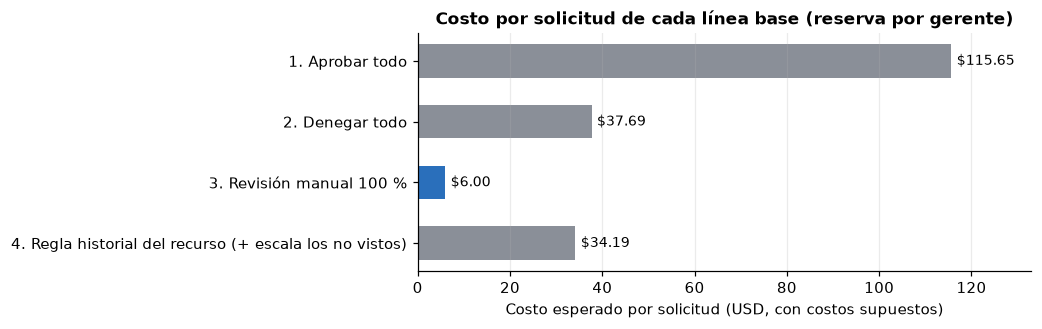

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 2.8))
vals = base["Costo por solicitud"]
colors = [GRAY, GRAY, BLUE, GRAY]   # azul = la referencia a vencer (revisión manual)
ax.barh(vals.index[::-1], vals.values[::-1], color=colors[::-1], height=0.55)
for yy, v in enumerate(vals.values[::-1]):
    ax.text(v + vals.max() * 0.01, yy, f"${v:,.2f}", va="center", fontsize=9)
ax.set_xlim(0, vals.max() * 1.15); ax.grid(axis="y", visible=False)
ax.set_xlabel("Costo esperado por solicitud (USD, con costos supuestos)")
ax.set_title("Costo por solicitud de cada línea base (reserva por gerente)")
plt.show()

**Lectura de las líneas base (hallazgo importante).**

- *Aprobar todo* es la peor opción con estos costos (≈ $116 por solicitud): 379 concesiones indebidas en la reserva.
- *Denegar todo* es absurdo operativamente, pero aun así es más barato que aprobar todo: **el FP pesa tanto que "ante la duda, denegar" gana**.
- La *regla del historial del recurso* aplicada con el umbral estricto `t*` solo logra ≈ $34 por solicitud: casi no comete FP (29) pero **bloquea a ~4.000 usuarios legítimos** porque el umbral es muy alto y el suavizado penaliza a los recursos con pocas solicitudes.
- La **revisión manual 100 % cuesta $6 por solicitud** y es la referencia a vencer. Un modelo automático solo aporta si su costo esperado queda por debajo de eso;
  lo realista es una política **híbrida**: aprobar/denegar automáticamente los casos de alta confianza y **escalar a un humano la zona gris**, de modo que el costo sea menor que revisar todo.

*(Cifras de la reserva de este notebook, con costos supuestos; cambian si cambian los costos.)*

## 6. Métrica de éxito

| | Métrica | Por qué |
|---|---|---|
| **Principal** | **Costo esperado por solicitud** con la matriz de la sección 3, al umbral de decisión elegido en validación | Es la única métrica que traduce los errores a dinero y respeta que FP y FN no cuestan lo mismo |
| Secundarias | ROC-AUC; PR-AUC de la clase *denegar*; recall de *denegar* (cuántos accesos indebidos se detectan); % de solicitudes resueltas sin humano | AUC mide el ordenamiento sin fijar umbral; el recall de la clase minoritaria es el que protege a la empresa |
| **No se usa** | Accuracy | Un modelo trivial ya obtiene ~94 % |

**Criterio de éxito.** El modelo es útil si su costo esperado por solicitud es **menor que el de la mejor línea base** de la sección 5
(en particular, menor que los ≈ $6 por solicitud de la revisión manual al 100 %, quizá con una política híbrida que escale la zona gris a un humano) y se mantiene al variar la razón `C_FP/C_FN` en la sensibilidad.

## 7. Riesgos, límites y supuestos

- **Costos supuestos:** C_FP, C_FN y C_REV no están en los datos. Validarlos antes de comunicar cifras a la dirección.
- **Etiqueta = decisión humana histórica.** `ACTION` dice qué *decidió un revisor*, no qué era *correcto*. Si los revisores se equivocaron o fueron sesgados, el modelo lo aprende. Antes de automatizar hay que auditar una muestra.
- **Fuga por partición:** un mismo gerente y un mismo recurso aparecen muchas veces. Partir por fila infla el desempeño (se demuestra en `03_preprocesamiento`). La partición es **por `MGR_ID`**.
- **Variables anónimas:** todo son códigos; no se puede interpretar el *significado* de un rol. La explicabilidad será por patrón (p. ej. "este recurso casi siempre se aprueba para este departamento").
- **Equidad / uso responsable:** el modelo no debe usarse para sancionar a personas; ayuda a priorizar la revisión. Las denegaciones automáticas deben poder apelarse.
- **Deriva:** en `test.csv` hay gerentes y familias de rol que no existen en `train.csv` (se mide en el EDA). El modelo debe tratar lo desconocido con prudencia (escalar a humano).
- **`test.csv` no tiene etiqueta**: no sirve para medir desempeño; solo para generar predicciones.

## 8. Decisiones del caso (copiar a `reports/00_caso.md` y a la sección 7 de `especificacion-proyecto.md`)

| # | Decisión | Motivo |
|---|---|---|
| 1 | Clase positiva = **aprobar** (`ACTION=1`); FP = concesión indebida, FN = bloqueo legítimo | Alinea el lenguaje de la matriz con el riesgo del negocio |
| 2 | Métrica principal = **costo esperado por solicitud**; accuracy descartada | 94,2 % de las solicitudes se aprueban: accuracy no discrimina |
| 3 | Umbral de decisión derivado de costos: `t* = C_FP/(C_FP+C_FN)`, a ajustar en validación | Costos asimétricos → umbral lejos de 0,5 |
| 4 | Partición por **gerente** (`MGR_ID`), reserva cerrada | Un gerente decide de forma correlacionada: partir por fila filtraría información |
| 5 | Costos como parámetros en `config/settings.py` con sensibilidad | No hay costos reales en los datos |
| 6 | Línea base a superar: la mejor entre revisión manual 100 % y la regla de historial del recurso | Un modelo debe justificar su complejidad frente a reglas simples |